# Algoritmo di Grover: studio sperimentale
## 1. Titolo e obiettivo del progetto
Studieremo amplificazione di ampiezza, overshooting e scaling con un'implementazione manuale in Python e Qiskit. Questo notebook costituisce la struttura iniziale per una futura relazione scientifica: in questa fase componiamo Grover con oracle e diffusore manuali e verifichiamo amplificazione e overshooting tramite Statevector.
Ora eseguiamo anche il primo esperimento statistico ideale con misure e 4096 shots.
La seconda modalità sperimentale usa il profilo di rumore IBM FakeManilaV2.
Le sezioni 11 e 12 studiano inoltre lo scaling ideale fino a n=7 e il caso di più soluzioni.

## 2. Descrizione sintetica dell'esperimento
Confronteremo la probabilità di trovare una soluzione marcata al variare delle iterazioni, del numero di qubit e del numero di soluzioni. Partiremo dalla simulazione ideale, aggiungeremo rumore e valuteremo eventualmente hardware IBM. Le funzioni high-level potranno servire in seguito come validazione.

Confrontiamo le verifiche esatte Statevector con frequenze da 4096 shots su Aer ideale. Il rumore viene studiato nella sezione 10; hardware reale resta uno sviluppo futuro.

## 3. Import e configurazione ambiente
Carichiamo solo le librerie necessarie alla struttura e alle verifiche dei due operatori e stampiamo le versioni per rendere tracciabile l'ambiente. Selezionare il kernel **Python (Grover)**, oppure l'interprete `.venv/Scripts/python.exe`.

Usiamo `AerSimulator` dal pacchetto separato `qiskit_aer`, compatibile con Qiskit 2.x; in questa fase usiamo `transpile` e `backend.run`. Riferimento: [documentazione ufficiale AerSimulator](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html). Il profilo di rumore viene caricato nella sezione 10; non usiamo strumenti IBM o algoritmi preconfezionati.

In [123]:
import sys
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

LIBRARY_VERSIONS = {
    name: version(name)
    for name in ("qiskit", "qiskit-aer", "numpy", "pandas", "matplotlib")
}
print(f"Python: {sys.version.split()[0]}")
for name, installed_version in LIBRARY_VERSIONS.items():
    print(f"{name}: {installed_version}")
from qiskit.quantum_info import Operator, Statevector
from IPython.display import display
from qiskit import transpile
from time import perf_counter
from pathlib import Path
from collections.abc import Mapping
import json


Python: 3.12.0
qiskit: 2.5.2
qiskit-aer: 0.17.2
numpy: 2.4.4
pandas: 3.0.2
matplotlib: 3.10.9


## 4. Parametri globali
Centralizziamo i valori iniziali e il seme casuale. Gli stati sono stringhe nell'ordine Qiskit `q[n-1]...q[0]`: il bit più a destra corrisponde al qubit 0. Partiamo da una soluzione; la tupla consentirà di rappresentarne più di una.

Il seme sarà passato anche al simulatore e al transpiler nei futuri esperimenti. Non rende riproducibili rumore fisico o tempi di esecuzione.

In [124]:
RANDOM_SEED = 42
SHOTS_DEFAULT = 4096
N_VALUES = (2, 3, 4, 5, 6)  # Dimensioni per gli esperimenti ideali con shots.
N_QUBITS_DEFAULT = N_VALUES[1]
MARKED_STATE_DEFAULT = "101"
MARKED_STATES_DEFAULT = (MARKED_STATE_DEFAULT,)
SEARCH_SPACE_SIZE = 2 ** N_QUBITS_DEFAULT
N_SOLUTIONS_DEFAULT = len(MARKED_STATES_DEFAULT)

rng = np.random.default_rng(RANDOM_SEED)


def validate_problem(n: int, marked_states: list[str] | tuple[str, ...]) -> None:
    """Controlla dimensione, alfabeto binario e unicità delle soluzioni."""
    if isinstance(n, bool) or not isinstance(n, int) or n < 1:
        raise ValueError("n deve essere un intero positivo.")
    if not isinstance(marked_states, (list, tuple)):
        raise ValueError("marked_states deve essere una lista o tupla di bitstring.")
    if not marked_states:
        raise ValueError("Occorre almeno una soluzione marcata.")
    if any(not isinstance(state, str) or len(state) != n
           or set(state) - {"0", "1"} for state in marked_states):
        raise ValueError("Ogni stato deve essere una stringa binaria di lunghezza n.")
    if len(set(marked_states)) != len(marked_states):
        raise ValueError("Gli stati marcati devono essere distinti.")


def make_ideal_backend(seed: int = RANDOM_SEED) -> AerSimulator:
    """Crea un simulatore ideale riproducibile con la base di porte del progetto."""
    return AerSimulator(method="statevector", basis_gates=["u", "cx"], seed_simulator=seed)


validate_problem(N_QUBITS_DEFAULT, MARKED_STATES_DEFAULT)

### Tabella centrale degli esperimenti
Schema e impostazioni comuni per le esecuzioni con shots.

In [125]:
# Schema centrale: una riga per esecuzione statistica. Reset a ogni Run All.
RESULT_DTYPES = {
    "backend": "string", "mode": "string", "n": "Int64", "N": "Int64", "M": "Int64",
    "marked_states": "object", "k": "Int64", "shots": "Int64",
    "theoretical_probability": "Float64", "measured_success_probability": "Float64",
    "execution_time": "Float64", "depth": "Int64", "total_gate_count": "Int64",
    "two_qubit_gate_count": "Int64", "standard_error": "Float64",
    "seed": "Int64", "seed_transpiler": "Int64", "optimization_level": "Int64",
    "basis_gates": "object", "counts": "object", "normalized_counts": "object",
    "qiskit_version": "string", "qiskit_aer_version": "string",
}
RESULT_DTYPES.update({
    "p1": "Float64", "p2": "Float64", "readout_error": "Float64",
    "success_probability": "Float64", "expected_noisy_probability": "Float64",
    "actual_basis_gates": "string", "simulation_method": "string", "experiment_group": "string",
})
def make_results_dataframe() -> pd.DataFrame:
    return pd.DataFrame({name: pd.Series(dtype=dtype) for name, dtype in RESULT_DTYPES.items()})

results_df = make_results_dataframe()
IDEAL_BASIS_GATES = ("u", "cx")
IDEAL_OPTIMIZATION_LEVEL = 1

## 5. Costruzione dell'oracolo
Per uno stato marcato $O=I-2|w\rangle\langle w|$. L'ortonormalità della base dà
$O|x\rangle=(1-2\delta_{xw})|x\rangle$: solo l'ampiezza marcata cambia segno.
Per un insieme $W$ di stati distinti, $O_W=I-2\sum_{w\in W}|w\rangle\langle w|$.
Per ogni bitstring applichiamo X sui bit zero, una fase multi-controllata su
$|11\ldots1\rangle$, poi annulliamo gli X. Le riflessioni sui diversi stati marcati
si compongono senza interferire; i duplicati sono rifiutati perché annullerebbero il cambio di segno.

**Endianness:** le stringhe seguono l'ordine `q[n-1]...q[0]`: il bit a destra è il qubit 0.
`"101"` indica $q_2=1,q_1=0,q_0=1$ e l'indice `int("101", 2) = 5` nello Statevector.
`"001"` indica $q_2=0,q_1=0,q_0=1$, indice 1, non 4. Usiamo
`enumerate(reversed(state))` per associare caratteri e qubit. Nei diagrammi `q_0` è in alto.
Riferimento: [ordine dei bit in Qiskit](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering).

L'helper condiviso usa Z per n=1, CZ per n=2, e H–MCX–H sul target per n>=3.
Poiché $HXH=Z$, questa sequenza cambia segno solo quando tutti i qubit valgono 1.
Non usiamo ancille o GroverOperator.

In [126]:
def apply_multi_controlled_z(circuit: QuantumCircuit) -> None:
    """Applica in-place la fase -1 su |11...1> a tutti i qubit."""
    n = circuit.num_qubits
    if n < 1:
        raise ValueError("La Z multi-controllata richiede almeno un qubit.")
    if n == 1:
        circuit.z(0)
    elif n == 2:
        circuit.cz(0, 1)
    else:
        target = n - 1
        circuit.h(target)
        circuit.mcx(list(range(target)), target)
        circuit.h(target)


def build_phase_oracle(
    n_qubits: int, marked_states: list[str] | tuple[str, ...]
) -> QuantumCircuit:
    """Costruisce O_W; stringhe in ordine q[n-1]...q[0]."""
    validate_problem(n_qubits, marked_states)
    circuit = QuantumCircuit(n_qubits, name="O")
    for state in marked_states:
        zero_qubits = [q for q, bit in enumerate(reversed(state)) if bit == "0"]
        for q in zero_qubits:
            circuit.x(q)
        apply_multi_controlled_z(circuit)
        for q in reversed(zero_qubits):
            circuit.x(q)
    return circuit


def build_oracle(n: int, marked_states: list[str] | tuple[str, ...]) -> QuantumCircuit:
    """Alias compatibile con la firma già prevista nel notebook."""
    return build_phase_oracle(n, marked_states)

## 6. Costruzione del diffusore
Lo stato uniforme è $|s\rangle=H^{\otimes n}|0\ldots0\rangle$ e
$D=2|s\rangle\langle s|-I$. Scrivendo $|\psi\rangle=\alpha|s\rangle+|\psi_\perp\rangle$,
si ha $D|\psi\rangle=\alpha|s\rangle-|\psi_\perp\rangle$: la componente lungo lo stato
uniforme rimane invariata, quella ortogonale cambia segno. È una riflessione rispetto a $|s\rangle$.
Per $N=2^n$, ampiezze $a_x$ e media $\bar a=N^{-1}\sum_x a_x$, segue
$a'_x=2\bar a-a_x$ (**inversion about the mean**), anche per ampiezze complesse.

La sequenza H, X, multi-controlled Z, X, H realizza
$H^{\otimes n}(I-2|0\ldots0\rangle\langle0\ldots0|)H^{\otimes n}=-D$.
Includiamo `global_phase = np.pi` per ottenere esattamente $D$ e confrontare direttamente le ampiezze.
Una fase globale $e^{i\phi}$ non cambia le probabilità: $|e^{i\phi}a_x|^2=|a_x|^2$.
Le fasi relative tra componenti, invece, possono cambiare l'interferenza.

In [127]:
def build_diffuser(n_qubits: int) -> QuantumCircuit:
    """Costruisce D = 2|s><s| - I, inclusa la fase globale."""
    if isinstance(n_qubits, bool) or not isinstance(n_qubits, int) or n_qubits < 1:
        raise ValueError("n_qubits deve essere un intero positivo.")
    circuit = QuantumCircuit(n_qubits, name="D")
    circuit.h(range(n_qubits))
    circuit.x(range(n_qubits))
    apply_multi_controlled_z(circuit)
    circuit.x(range(n_qubits))
    circuit.h(range(n_qubits))
    circuit.global_phase = np.pi
    return circuit

### 6.1 Circuiti a tre qubit: stato marcato |101⟩
I diagrammi testuali mostrano le porte senza dipendenze grafiche aggiuntive.

In [128]:
oracle_example = build_phase_oracle(3, ["101"])
diffuser_example = build_diffuser(3)
print("Phase oracle, stato marcato |101>:")
print(oracle_example.draw(output="text"))
print("Diffusore (fase globale pi inclusa):")
print(diffuser_example.draw(output="text"))

Phase oracle, stato marcato |101>:
                    
q_0: ───────■───────
     ┌───┐  │  ┌───┐
q_1: ┤ X ├──■──┤ X ├
     ├───┤┌─┴─┐├───┤
q_2: ┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘
Diffusore (fase globale pi inclusa):
global phase: π
     ┌───┐┌───┐          ┌───┐┌───┐     
q_0: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤       │  ├───┤├───┤     
q_1: ┤ H ├┤ X ├───────■──┤ X ├┤ H ├─────
     ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐
q_2: ┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘└───┘└───┘└───┘


### 6.2 Verifica delle ampiezze e tabella
Prepariamo $|s\rangle$ con Hadamard e confrontiamo le ampiezze con formule indipendenti dai circuiti.
Per $N=8,M=1$, dopo l'oracolo $\bar a=3/(4\sqrt8)$; dopo il diffusore
l'ampiezza marcata vale $5/(2\sqrt8)$ e le altre $1/(2\sqrt8)$.
Gli assert usano tolleranza assoluta $10^{-12}$ e relativa zero.

In [129]:
ATOL = 1e-12
prepare_uniform = QuantumCircuit(3)
prepare_uniform.h(range(3))
before_oracle = Statevector.from_instruction(prepare_uniform)
after_oracle = before_oracle.evolve(oracle_example)
after_diffuser = after_oracle.evolve(diffuser_example)
expected_before = np.full(8, 1 / np.sqrt(8), dtype=complex)
expected_after = expected_before.copy()
expected_after[5] *= -1
expected_diffused = 2 * expected_after.mean() - expected_after
np.testing.assert_allclose(before_oracle.data, expected_before, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_oracle.data, expected_after, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data, expected_diffused, atol=ATOL, rtol=0)
np.testing.assert_allclose(after_diffuser.data[5], 5 / (2 * np.sqrt(8)), atol=ATOL, rtol=0)
np.testing.assert_allclose(np.linalg.norm(after_diffuser.data), 1, atol=ATOL, rtol=0)
amplitudes_df = pd.DataFrame({
    "basis_state": [format(i, "03b") for i in range(8)],
    "amplitude_before_oracle": np.real_if_close(before_oracle.data),
    "amplitude_after_oracle": np.real_if_close(after_oracle.data),
    "amplitude_after_diffuser": np.real_if_close(after_diffuser.data),
})
display(amplitudes_df)

,basis_state,amplitude_before_oracle,amplitude_after_oracle,amplitude_after_diffuser
0,000,0.353553,0.353553,0.176777
1,001,0.353553,0.353553,0.176777
2,010,0.353553,0.353553,0.176777
3,011,0.353553,0.353553,0.176777
4,100,0.353553,0.353553,0.176777
5,101,0.353553,-0.353553,0.883883
6,110,0.353553,0.353553,0.176777
7,111,0.353553,0.353553,0.176777


## 7. Costruzione dell'algoritmo di Grover
QuantumCircuit parte da |0...0⟩; gli Hadamard preparano lo stato uniforme.
Ogni iterazione applica prima l'oracolo manuale, poi il diffusore manuale.
Con zero iterazioni rimane la sovrapposizione uniforme. Le misure opzionali associano
il qubit i al bit classico i, mantenendo le stringhe nell'ordine q[n-1]...q[0].
Per Statevector usiamo sempre measure=False.

In [130]:
def build_grover_circuit(
    n_qubits: int,
    marked_states: list[str] | tuple[str, ...],
    iterations: int,
    measure: bool = True,
) -> QuantumCircuit:
    """Prepara lo stato uniforme, applica (D O)^iterations e misura opzionalmente."""
    validate_problem(n_qubits, marked_states)
    if isinstance(iterations, bool) or not isinstance(iterations, (int, np.integer)) or iterations < 0:
        raise ValueError("iterations deve essere un intero non negativo.")
    if not isinstance(measure, bool):
        raise ValueError("measure deve essere booleano.")
    circuit = QuantumCircuit(n_qubits, n_qubits if measure else 0, name="Grover")
    circuit.h(range(n_qubits))
    if iterations:
        oracle = build_phase_oracle(n_qubits, marked_states)
        diffuser = build_diffuser(n_qubits)
        for _ in range(iterations):
            circuit.compose(oracle, inplace=True)
            circuit.compose(diffuser, inplace=True)
    if measure:
        circuit.measure(range(n_qubits), range(n_qubits))
    return circuit

## 8. Verifica teorica e geometria
Per $0<M<N$ definiamo $|G\rangle=M^{-1/2}\sum_{w\in W}|w\rangle$ e
$|B\rangle=(N-M)^{-1/2}\sum_{x\notin W}|x\rangle$.
Lo stato uniforme è $|s\rangle=\cos\theta|B\rangle+\sin\theta|G\rangle$,
con $\theta=\arcsin\sqrt{M/N}$ e $N=2^n$.
Oracle e diffusore mantengono lo stato nel sottospazio generato da $|B\rangle,|G\rangle$.
La loro composizione $DO$ ruota di $2\theta$ verso le soluzioni a ogni iterazione:
$$|\psi_k\rangle=\cos((2k+1)\theta)|B\rangle+\sin((2k+1)\theta)|G\rangle,$$
quindi $P(k)=\sin^2((2k+1)\theta)$. Oltre il primo massimo la rotazione allontana
lo stato dalla direzione delle soluzioni: è l'**overshooting**. La probabilità poi oscilla;
non diminuisce indefinitamente. Se $M=N$, il successo è sempre 1 e bastano zero iterazioni.

Il primo massimo continuo è $k_*=\pi/(4\theta)-1/2$. Per $M/N\ll1$,
$\theta\simeq\sqrt{M/N}$, dunque $k_*\simeq(\pi/4)\sqrt{N/M}-1/2$;
la comune stima $(\pi/4)\sqrt{N/M}$ trascura anche il termine $-1/2$.
La funzione sceglie l'intero non negativo con probabilità maggiore tra floor e ceil di $k_*$;
a parità numerica sceglie il minore. È la scelta vicino al **primo** massimo,
non una ricerca illimitata su eventuali massimi successivi.

Riferimenti fuori dalla slide del corso: [analisi geometrica](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/analysis)
e [scelta delle iterazioni](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/number-of-iterations), IBM Quantum. 

In [131]:
def grover_theta(N: int, M: int) -> float:
    """Restituisce arcsin(sqrt(M/N)); richiede 1 <= M <= N interi."""
    if any(isinstance(v, bool) or not isinstance(v, (int, np.integer)) for v in (N, M)):
        raise ValueError("N e M devono essere interi.")
    if N < 1 or not 1 <= M <= N:
        raise ValueError("Occorre 1 <= M <= N.")
    return float(np.arcsin(np.sqrt(M / N)))


def theoretical_success_probability(N: int, M: int, k: int) -> float:
    """Probabilità ideale dopo k iterazioni intere non negative."""
    theta = grover_theta(N, M)
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 0:
        raise ValueError("k deve essere un intero non negativo.")
    if M == N:
        return 1.0
    return float(np.sin((2 * k + 1) * theta) ** 2)


def optimal_grover_iterations(N: int, M: int) -> int:
    """Sceglie tra gli interi vicini al primo massimo; parità -> meno iterazioni."""
    theta = grover_theta(N, M)
    if M == N:
        return 0
    continuous = np.pi / (4 * theta) - 0.5
    lower = max(0, int(np.floor(continuous)))
    upper = max(0, int(np.ceil(continuous)))
    p_lower = theoretical_success_probability(N, M, lower)
    p_upper = theoretical_success_probability(N, M, upper)
    return upper if p_upper > p_lower + 1e-14 else lower


iteration_choices_df = pd.DataFrame([
    {"n": n, "N": 2 ** n, "M": 1,
     "approximate_k": np.pi / 4 * np.sqrt(2 ** n),
     "first_continuous_maximum": np.pi / (4 * grover_theta(2 ** n, 1)) - 0.5,
     "chosen_k": optimal_grover_iterations(2 ** n, 1)}
    for n in (2, 3, 4)
])
display(iteration_choices_df)

,n,N,M,approximate_k,first_continuous_maximum,chosen_k
0,2,4,1,1.570796,1.000000,1
1,3,8,1,2.221441,1.673408,2
2,4,16,1,3.141593,2.608269,3


## 9. Verifiche ideali con Statevector
Per $N=4,M=1$, $\theta=\pi/6$ e $3\theta=\pi/2$: una singola iterazione
produce lo stato marcato con probabilità 1. Verifichiamo anche le ampiezze dello stato completo.
La tabella confronta teoria e simulazione per n=2,3,4 e k=0,...,8, includendo il primo
massimo e l'overshooting. Il successo è la somma delle probabilità degli stati marcati.
Usiamo tolleranza assoluta $10^{-12}$ e relativa zero; non c'è incertezza da shots.

In [132]:
special_state = Statevector.from_instruction(build_grover_circuit(2, ["01"], 1, False))
np.testing.assert_allclose(special_state.data, Statevector.from_label("01").data, atol=ATOL, rtol=0)
np.testing.assert_allclose(theoretical_success_probability(4, 1, 1), 1, atol=ATOL, rtol=0)
assert optimal_grover_iterations(4, 1) == 1
print(f"N=4, M=1, k=1: P(|01>) = {special_state.probabilities()[1]:.15f}")

single_solution_cases = {2: ["01"], 3: ["101"], 4: ["0101"]}
comparison_rows = []
for n, marked in single_solution_cases.items():
    N, M = 2 ** n, len(marked)
    indices = [int(state, 2) for state in marked]
    for k in range(9):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        probability = float(state.probabilities()[indices].sum())
        theory = theoretical_success_probability(N, M, k)
        np.testing.assert_allclose(probability, theory, atol=ATOL, rtol=0)
        np.testing.assert_allclose(np.linalg.norm(state.data), 1, atol=ATOL, rtol=0)
        comparison_rows.append({
            "n": n, "N": N, "M": M, "k": k,
            "theoretical_probability": theory, "statevector_probability": probability,
            "absolute_error": abs(probability - theory),
        })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
print(f"Errore assoluto massimo: {comparison_df.absolute_error.max():.3e}")

# Regressioni: zero iterazioni, più soluzioni, n=1 e tutte le soluzioni.
for n, marked in ((1, ["0"]), (1, ["0", "1"]), (3, ["001", "110"])):
    for k in range(5):
        state = Statevector.from_instruction(build_grover_circuit(n, marked, k, False))
        np.testing.assert_allclose(
            state.probabilities()[[int(w, 2) for w in marked]].sum(),
            theoretical_success_probability(2 ** n, len(marked), k), atol=ATOL, rtol=0,
        )
zero_circuit = build_grover_circuit(3, ["001"], 0, False)
np.testing.assert_allclose(Statevector.from_instruction(zero_circuit).data,
                           np.full(8, 1 / np.sqrt(8)), atol=ATOL, rtol=0)
assert zero_circuit.num_clbits == 0
measured = build_grover_circuit(3, ["001"], 2)
measurements = [item for item in measured.data if item.operation.name == "measure"]
assert measured.num_clbits == 3 and len(measurements) == 3
assert [(measured.find_bit(item.qubits[0]).index, measured.find_bit(item.clbits[0]).index)
        for item in measurements] == [(0, 0), (1, 1), (2, 2)]
np.testing.assert_allclose(
    Operator(measured.remove_final_measurements(inplace=False)).data,
    Operator(build_grover_circuit(3, ["001"], 2, False)).data, atol=ATOL, rtol=0,
)
assert optimal_grover_iterations(8, 8) == 0
assert optimal_grover_iterations(8, 4) == 0  # Parità: P(k)=1/2.
for bad_call in (
    lambda: build_grover_circuit(2, ["01"], -1),
    lambda: build_grover_circuit(2, ["01"], 1.5),
    lambda: build_grover_circuit(2, ["01"], True),
    lambda: build_grover_circuit(2, ["01"], 1, "yes"),
    lambda: theoretical_success_probability(4, 1, -1),
    lambda: theoretical_success_probability(4, 1, 0.5),
    lambda: grover_theta(0, 1), lambda: grover_theta(4, 0),
    lambda: grover_theta(4, 5), lambda: grover_theta(4.0, 1),
):
    try:
        bad_call()
    except ValueError:
        pass
    else:
        raise AssertionError("Input non valido accettato.")
print("Il test conferma che il circuito quantistico costruito in Qiskit riproduce con infinita precisione la teoria dell'algoritmo di Grover.")

N=4, M=1, k=1: P(|01>) = 0.999999999999999


,n,N,M,k,theoretical_probability,statevector_probability,absolute_error
0,2,4,1,0,0.250000,0.250000,1.110223e-16
1,2,4,1,1,1.000000,1.000000,8.881784e-16
2,2,4,1,2,0.250000,0.250000,5.551115e-17
3,2,4,1,3,0.250000,0.250000,6.661338e-16
4,2,4,1,4,1.000000,1.000000,2.886580e-15
5,2,4,1,5,0.250000,0.250000,5.551115e-16
6,2,4,1,6,0.250000,0.250000,1.831868e-15
7,2,4,1,7,1.000000,1.000000,4.662937e-15
8,2,4,1,8,0.250000,0.250000,1.110223e-15
9,3,8,1,0,0.125000,0.125000,8.326673e-17


Errore assoluto massimo: 2.176e-14
Il test conferma che il circuito quantistico costruito in Qiskit riproduce con infinita precisione la teoria dell'algoritmo di Grover.


### 9.1 Primo esperimento statistico ideale
Ora passiamo dalle probabilità esatte alle **misure simulate**. Ogni circuito viene
eseguito 4096 volte (*shots*) su Aer, senza rumore.

Per ogni numero di qubit da 2 a 6 proviamo le iterazioni vicine al primo massimo
teorico. Lo stato cercato è sempre `00...01`.

L'esperimento segue tre passaggi:
1. Costruire e simulare il circuito di Grover.
2. Contare quante misure restituiscono lo stato cercato.
3. Confrontare la frequenza di successo con la probabilità teorica.

La frequenza è semplicemente **successi / shots**: per esempio, 3072 successi su
4096 misure danno 0,75. Con un numero finito di misure sono normali piccoli scarti
dalla teoria, anche senza rumore.

La funzione seguente raccoglie una singola esecuzione; la cella successiva la
ripete per i diversi valori di `n` e `k` e mostra una tabella riassuntiva.
I campi tecnici nel dizionario finale servono ai confronti e ai CSV delle sezioni
successive. L'errore standard stima la fluttuazione statistica della frequenza:
$\sqrt{\hat p(1-\hat p)/S}$. Non è un intervallo di confidenza; ai valori 0 e 1
si annulla senza dimostrare che l'incertezza sia nulla.


In [133]:
def success_probability(probabilities, marked_states):
    """Somma le probabilità degli stati cercati in una distribuzione normalizzata."""
    return float(sum(probabilities.get(state, 0.0) for state in marked_states))


def run_ideal_experiment(n_qubits, marked_states, iterations, shots, seed):
    """Simula Grover senza rumore e raccoglie il risultato."""
    # 1. Costruiamo il circuito e lo compiliamo per il simulatore.
    circuit = build_grover_circuit(n_qubits, marked_states, iterations, measure=True)
    backend = make_ideal_backend(seed)
    compiled = transpile(circuit, backend,
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)

    # 2. Eseguiamo le misure e calcoliamo la frequenza di successo.
    start = perf_counter()
    result = backend.run(compiled, shots=shots, seed_simulator=seed).result()
    execution_time = perf_counter() - start  # Tempo del simulatore, non di una QPU.
    counts = dict(result.get_counts())
    successes = sum(counts.get(state, 0) for state in marked_states)
    measured = successes / shots

    # 3. Calcoliamo la probabilità teorica da confrontare con le misure.
    N, M = 2 ** n_qubits, len(marked_states)
    theory = theoretical_success_probability(N, M, iterations)

    # Dati di supporto per i successivi confronti di risorse e per i CSV.
    normalized = {state: count / shots for state, count in counts.items()}
    gates_only = compiled.remove_final_measurements(inplace=False)
    gate_instructions = list(gates_only.data)
    return {
        "backend": backend.name, "mode": "ideal_shots", "n": n_qubits, "N": N, "M": M,
        "marked_states": tuple(marked_states), "k": iterations, "shots": int(shots),
        "theoretical_probability": theory, "measured_success_probability": measured,
        "execution_time": execution_time,
        "depth": gates_only.depth(),
        "total_gate_count": len(gate_instructions),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gate_instructions),
        "standard_error": float(np.sqrt(measured * (1 - measured) / shots)),
        "seed": int(seed), "seed_transpiler": int(seed),
        "optimization_level": IDEAL_OPTIMIZATION_LEVEL, "basis_gates": IDEAL_BASIS_GATES,
        "counts": counts, "normalized_counts": normalized,
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
    }


In [134]:
# Ripetiamo l'esperimento vicino al massimo teorico, includendo il calo successivo.
experiment_rows = []
for n in N_VALUES:
    marked = (format(1, f"0{n}b"),)  # Stato cercato: 00...01.
    k_opt = optimal_grover_iterations(2 ** n, 1)
    for k in range(max(0, k_opt - 2), k_opt + 3):
        seed = RANDOM_SEED + 100 * n + k
        row = run_ideal_experiment(n, marked, k, SHOTS_DEFAULT, seed)
        experiment_rows.append(row)

# Conserviamo tutti i dati per le sezioni successive, ma mostriamo solo l'essenziale.
results_df = pd.DataFrame(experiment_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
summary = results_df[["n", "k", "shots", "theoretical_probability",
                      "measured_success_probability"]].copy()
summary.columns = ["Qubit", "Iterazioni", "Shots", "Probabilità teorica", "Frequenza misurata"]
display(summary.round(4))
print("Confrontando le ultime due colonne si possono notare i piccoli scarti.")
print("Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.")


,Qubit,Iterazioni,Shots,Probabilità teorica,Frequenza misurata
0,2,0,4096,0.25,0.2461
1,2,1,4096,1.0,1.0
2,2,2,4096,0.25,0.2449
3,2,3,4096,0.25,0.2498
4,3,0,4096,0.125,0.1257
5,3,1,4096,0.7813,0.7874
6,3,2,4096,0.9453,0.9441
7,3,3,4096,0.3301,0.3279
8,3,4,4096,0.0122,0.0137
9,4,1,4096,0.4727,0.4792


Confrontando le ultime due colonne si possono notare i piccoli scarti.
Per ogni numero di qubit, si osserva inoltre la crescita e il calo del successo attorno al massimo.


### 9.2 Ripetere lo stesso esperimento: fluttuazioni delle misure
Fissiamo **4 qubit**, lo stato cercato `0001` e **3 iterazioni**. Ripetiamo
lo stesso circuito **4 volte**, con **4096 shots per prova**.

La probabilità teorica resta sempre la stessa, circa **0,9613**. Cambiamo solo
il seme del simulatore per ottenere campioni diversi e riproducibili.
La frequenza misurata può essere maggiore o minore della probabilità teorica:
lo scarto è dovuto al numero finito di misure, anche in assenza di rumore.
Non è garantito che appena quattro prove mostrino entrambi i segni.

La tabella riporta i successi e lo scarto **frequenza misurata meno probabilità
teorica**. Il grafico ingrandisce la zona vicina al valore teorico per rendere
visibili le piccole differenze. Ogni punto rappresenta una prova completa,
non una singola misura. Queste ripetizioni sono raccolte separatamente in
`repeated_trials_df`.


,Prova,Seed,Shots,Successi,Teoria,Frequenza,Scarto
0,1,42,4096,3944,0.961319,0.962891,0.001572
1,2,43,4096,3957,0.961319,0.966064,0.004745
2,3,44,4096,3937,0.961319,0.961182,-0.000137
3,4,45,4096,3934,0.961319,0.960449,-0.000870


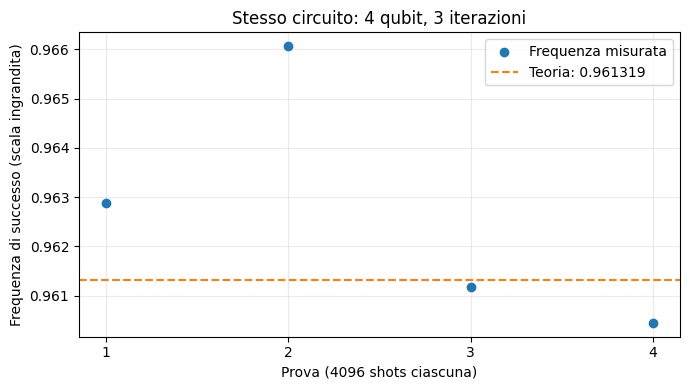

In [135]:
# Un solo circuito: cambiamo soltanto il campione di misure.
trial_n = 4
trial_k = 3
trial_target = "0001"
trial_shots = 4096
trial_seeds = [RANDOM_SEED + i for i in range(4)]

trial_backend = make_ideal_backend()
trial_circuit = build_grover_circuit(trial_n, [trial_target], trial_k)
trial_compiled = transpile(trial_circuit, trial_backend,
                           optimization_level=IDEAL_OPTIMIZATION_LEVEL,
                           seed_transpiler=RANDOM_SEED)
trial_theory = theoretical_success_probability(2 ** trial_n, 1, trial_k)

trial_rows = []
for trial, seed in enumerate(trial_seeds, start=1):
    counts = trial_backend.run(trial_compiled, shots=trial_shots,
                               seed_simulator=seed).result().get_counts()
    successes = counts.get(trial_target, 0)
    frequency = successes / trial_shots
    trial_rows.append({
        "Prova": trial, "Seed": seed, "Shots": trial_shots, "Successi": successes,
        "Teoria": trial_theory, "Frequenza": frequency,
        "Scarto": frequency - trial_theory,
    })

repeated_trials_df = pd.DataFrame(trial_rows)
display(repeated_trials_df.round(6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(repeated_trials_df["Prova"], repeated_trials_df["Frequenza"],
           label="Frequenza misurata", zorder=3)
ax.axhline(trial_theory, color="tab:orange", linestyle="--",
           label=f"Teoria: {trial_theory:.6f}")
ax.set(xticks=repeated_trials_df["Prova"], xlabel="Prova (4096 shots ciascuna)",
       ylabel="Frequenza di successo (scala ingrandita)",
       title="Stesso circuito: 4 qubit, 3 iterazioni")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 10. Simulazione con un fake backend IBM
Usiamo **FakeManilaV2**, un profilo salvato di un processore IBM da 5 qubit.
Aer costruisce dai suoi dati un modello approssimato di rumore delle porte,
rilassamento e lettura. Non serve un account IBM: la simulazione avviene in locale.
Non si tratta di una replica esatta o aggiornata del dispositivo reale.

Fissiamo **4 qubit**, stato cercato `0001` e **4096 shots**. Proviamo da **0 a 6
iterazioni**, includendo il massimo ideale a 3 iterazioni e il calo successivo.
Il profilo di rumore resta fisso: non scegliamo manualmente `p1` e `p2`.

Compiliamo per la topologia e le porte di Manila, poi eseguiamo **lo stesso circuito
compilato** sia con rumore sia senza. La tabella confronta teoria e frequenze misurate.

Nelle versioni attuali l'import proviene da `qiskit_ibm_runtime.fake_provider`.
Riferimento: [documentazione IBM sui fake backend](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/fake-provider).


In [136]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

fake_backend = FakeManilaV2()
noisy_sim = AerSimulator.from_backend(fake_backend)
noisy_sim.set_options(method="density_matrix", max_parallel_threads=1)
ideal_sim = AerSimulator(method="statevector")
print("Profilo:", fake_backend.name, "| Qubit disponibili:", fake_backend.num_qubits)
print("Data del profilo:", fake_backend.properties().last_update_date)

# Questi campi conservano nel CSV il confronto ideale e la provenienza del profilo.
RESULT_DTYPES.update({"compiled_ideal_frequency": "Float64",
                      "calibration_date": "string", "runtime_version": "string"})


def run_noisy_experiment(n_qubits, marked_states, iterations, shots, seed,
                         backend_profile=None, simulator=None):
    """Confronta lo stesso circuito con e senza rumore del profilo scelto."""
    backend_profile = fake_backend if backend_profile is None else backend_profile
    simulator = noisy_sim if simulator is None else simulator
    circuit = build_grover_circuit(n_qubits, marked_states, iterations)
    compiled = transpile(circuit, backend_profile, optimization_level=1,
                         seed_transpiler=RANDOM_SEED)

    start = perf_counter()
    counts = simulator.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()
    elapsed = perf_counter() - start
    ideal_counts = ideal_sim.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()
    measured = sum(counts.get(state, 0) for state in marked_states) / shots
    ideal_frequency = sum(ideal_counts.get(state, 0) for state in marked_states) / shots

    # Metadati per le tabelle e i CSV; le misure mantengono i bit logici originali.
    gates = compiled.remove_final_measurements(inplace=False)
    return {
        "backend": backend_profile.name, "mode": "noisy", "n": n_qubits,
        "N": 2 ** n_qubits, "M": len(marked_states), "marked_states": tuple(marked_states),
        "k": iterations, "shots": shots,
        "theoretical_probability": theoretical_success_probability(2 ** n_qubits, len(marked_states), iterations),
        "measured_success_probability": measured, "success_probability": measured,
        "compiled_ideal_frequency": ideal_frequency,
        "standard_error": float(np.sqrt(measured * (1 - measured) / shots)),
        "execution_time": elapsed, "depth": gates.depth(), "total_gate_count": len(gates.data),
        "two_qubit_gate_count": sum(item.operation.num_qubits == 2 for item in gates.data),
        "seed": seed, "seed_transpiler": RANDOM_SEED, "optimization_level": 1,
        "basis_gates": tuple(simulator.configuration().basis_gates),
        "actual_basis_gates": ",".join(sorted({item.operation.name for item in gates.data})),
        "counts": dict(counts), "normalized_counts": {state: count / shots for state, count in counts.items()},
        "qiskit_version": LIBRARY_VERSIONS["qiskit"], "qiskit_aer_version": LIBRARY_VERSIONS["qiskit-aer"],
        "simulation_method": "density_matrix", "experiment_group": "fake_backend",
        "calibration_date": backend_profile.properties().last_update_date.isoformat(),
        "runtime_version": version("qiskit-ibm-runtime"),
    }


Profilo: fake_manila | Qubit disponibili: 5
Data del profilo: 2024-05-27 15:27:23-03:00


In [137]:
# Conserva il batch ideale corrente; una riesecuzione non duplica il batch noisy.
ideal_results_df = results_df.loc[results_df["mode"] == "ideal_shots"].copy()
for column in ("p1", "p2", "readout_error"):
    ideal_results_df[column] = 0.0
ideal_results_df["success_probability"] = ideal_results_df.measured_success_probability
ideal_results_df["expected_noisy_probability"] = ideal_results_df.theoretical_probability
ideal_results_df["simulation_method"] = "statevector"
ideal_results_df["experiment_group"] = "ideal_scan"
ideal_basis = []
for row in ideal_results_df.itertuples():
    compiled = transpile(build_grover_circuit(int(row.n), row.marked_states, int(row.k), False),
                         make_ideal_backend(int(row.seed)),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=int(row.seed))
    ideal_basis.append(",".join(sorted({item.operation.name for item in compiled.data})))
ideal_results_df["actual_basis_gates"] = ideal_basis
ideal_results_df = ideal_results_df.reindex(columns=RESULT_DTYPES).astype(RESULT_DTYPES)

# Sette prove con lo stesso profilo di rumore.
noisy_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k)
              for k in range(7)]
noisy_results_df = pd.DataFrame(noisy_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
manila_results_df = noisy_results_df.copy()
results_df = pd.concat([ideal_results_df, noisy_results_df], ignore_index=True).astype(RESULT_DTYPES)
fake_summary = noisy_results_df[["k", "shots", "theoretical_probability",
                                 "compiled_ideal_frequency", "success_probability"]].copy()
fake_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(fake_summary.round(4))


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0637
1,1,4096,0.4727,0.481,0.2205
2,2,4096,0.9084,0.9158,0.2246
3,3,4096,0.9613,0.9619,0.1448
4,4,4096,0.5817,0.5815,0.0952
5,5,4096,0.1255,0.1355,0.0718
6,6,4096,0.0204,0.0173,0.0535


### 10.1 Grafici dei risultati
A sinistra confrontiamo teoria, frequenze ideali e frequenze con il rumore di Manila.
Le barre sul caso rumoroso indicano un errore standard stimato.
A destra mostriamo la distribuzione degli esiti con rumore per **3 iterazioni**:
la barra arancione corrisponde alla soluzione `0001`.


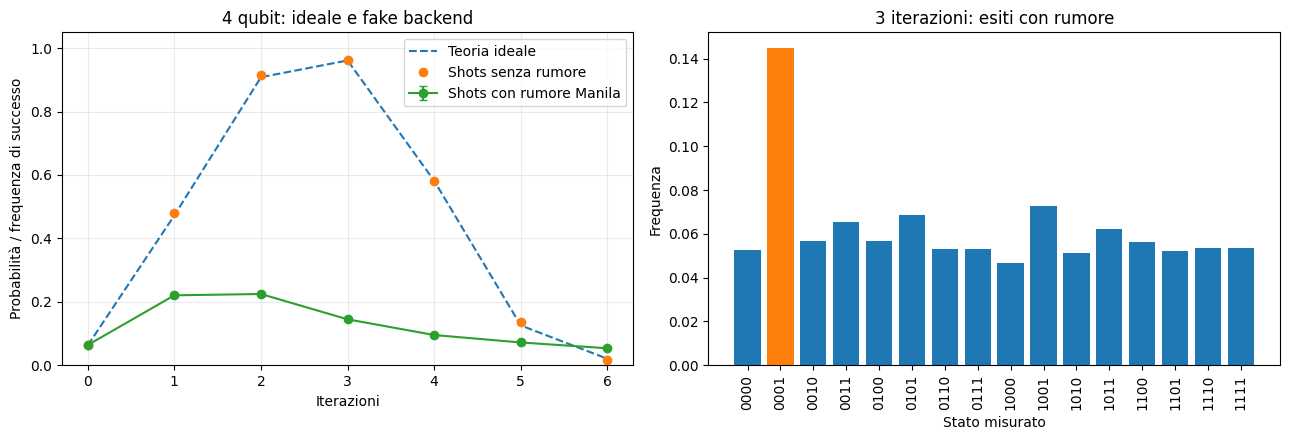

Miglior k misurato tra 0 e 6: 2; frequenza: 0.2246
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.


In [138]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(manila_results_df.k, manila_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(manila_results_df.k, manila_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(manila_results_df.k.to_numpy(dtype=float), manila_results_df.success_probability.to_numpy(dtype=float),
                 yerr=manila_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Manila")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e fake backend", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

example = manila_results_df[manila_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_fake = manila_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_fake.k)}; frequenza: {best_fake.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")


### 10.2 Interpretazione
Confrontiamo il successo ideale con quello del fake backend: gli errori di porte
e lettura possono ridurre la concentrazione delle misure sulla soluzione.
Aumentare le iterazioni aggiunge porte e quindi esposizione al rumore;
il massimo misurato può spostarsi rispetto a quello ideale.

I risultati dipendono dal profilo salvato, dalla compilazione e dagli shots.
Non sono misure su hardware reale e non prevedono esattamente le prestazioni attuali di Manila.


### 10.3 Stesso esperimento con FakeNairobiV2
Ripetiamo le sette prove con **FakeNairobiV2**, un profilo IBM da **7 qubit**.
Il problema resta identico: **4 qubit logici**, stato `0001`, da **0 a 6 iterazioni**
e **4096 shots**. Il circuito viene compilato per le porte e i collegamenti di Nairobi.

Confrontiamo lo stesso circuito compilato con e senza rumore. Come per Manila,
il grafico a sinistra mostra il successo e quello a destra gli esiti a 3 iterazioni.
La tabella finale affianca le frequenze rumorose dei due profili.
Le differenze riflettono sia i dati di calibrazione salvati sia la compilazione
sulle rispettive topologie: non sono una classifica delle prestazioni attuali dei dispositivi.


In [139]:
from qiskit_ibm_runtime.fake_provider import FakeNairobiV2

nairobi_backend = FakeNairobiV2()
nairobi_sim = AerSimulator.from_backend(nairobi_backend)
nairobi_sim.set_options(method="density_matrix", max_parallel_threads=1)
print("Profilo:", nairobi_backend.name, "| Qubit disponibili:", nairobi_backend.num_qubits)
print("Data del profilo:", nairobi_backend.properties().last_update_date)

nairobi_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k,
                                     backend_profile=nairobi_backend, simulator=nairobi_sim)
                for k in range(7)]
nairobi_results_df = pd.DataFrame(nairobi_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
nairobi_summary = nairobi_results_df[["k", "shots", "theoretical_probability",
                                    "compiled_ideal_frequency", "success_probability"]].copy()
nairobi_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(nairobi_summary.round(4))

# Conserviamo entrambi i profili nel CSV, senza duplicarli rieseguendo questa cella.
noisy_results_df = pd.concat([manila_results_df, nairobi_results_df], ignore_index=True).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df["mode"] != "noisy"], noisy_results_df],
                       ignore_index=True).astype(RESULT_DTYPES)


Profilo: fake_nairobi | Qubit disponibili: 7
Data del profilo: 2024-05-27 15:45:40-03:00


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0635
1,1,4096,0.4727,0.4885,0.3081
2,2,4096,0.9084,0.9097,0.4038
3,3,4096,0.9613,0.9604,0.3057
4,4,4096,0.5817,0.5757,0.1777
5,5,4096,0.1255,0.1226,0.0886
6,6,4096,0.0204,0.0171,0.0693


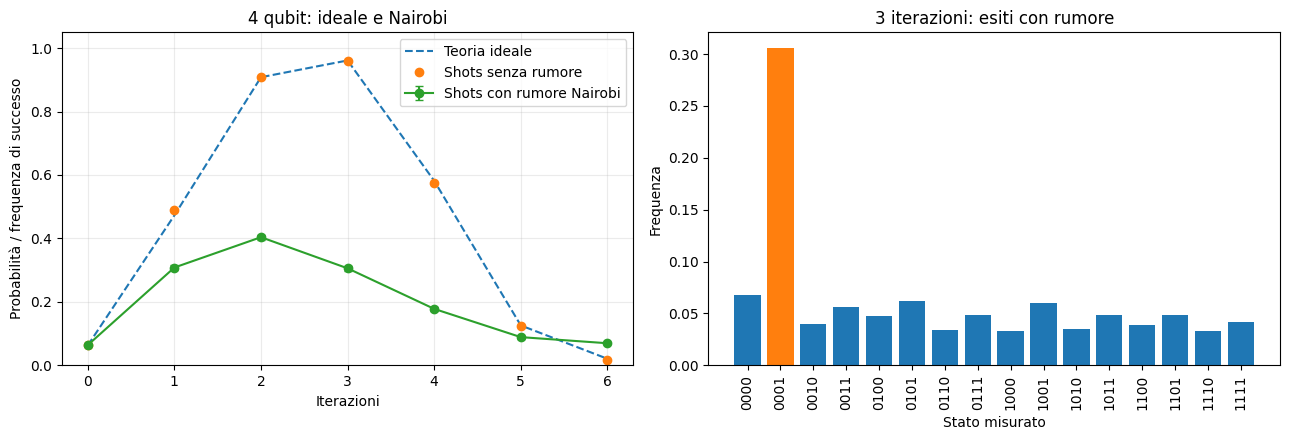

Miglior k misurato tra 0 e 6: 2; frequenza: 0.4038
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.
Confronto delle frequenze con rumore, a parita' di problema e shots:


backend,fake_manila,fake_nairobi
Iterazioni,,
0,0.0637,0.0635
1,0.2205,0.3081
2,0.2246,0.4038
3,0.1448,0.3057
4,0.0952,0.1777
5,0.0718,0.0886
6,0.0535,0.0693


In [140]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(nairobi_results_df.k, nairobi_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(nairobi_results_df.k, nairobi_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(nairobi_results_df.k.to_numpy(dtype=float), nairobi_results_df.success_probability.to_numpy(dtype=float),
                 yerr=nairobi_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Nairobi")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e Nairobi", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

nairobi_example = nairobi_results_df[nairobi_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [nairobi_example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_nairobi = nairobi_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_nairobi.k)}; frequenza: {best_nairobi.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")

print("Confronto delle frequenze con rumore, a parita' di problema e shots:")
backend_comparison = noisy_results_df.pivot(index="k", columns="backend", values="success_probability")
backend_comparison.index.name = "Iterazioni"
display(backend_comparison.round(4))


### 10.4 Stesso esperimento con FakeMumbaiV2
Ripetiamo le prove con **FakeMumbaiV2**, un profilo IBM da **27 qubit**.
Il problema resta di **4 qubit logici**, con stato cercato `0001`, da **0 a 6
iterazioni** e **4096 shots** per prova. Compiliamo per la topologia di Mumbai
e confrontiamo lo stesso circuito con e senza il suo rumore.

Aer esclude dalla simulazione i qubit inutilizzati; i qubit eventualmente
coinvolti nello spostamento degli stati durante la compilazione restano inclusi.
Tabella e grafici seguono lo stesso formato dei precedenti sottocapitoli.
La tabella finale confronta **Manila, Nairobi e Mumbai**: sono profili salvati,
non misure delle prestazioni attuali dei dispositivi reali.


In [141]:
from qiskit_ibm_runtime.fake_provider import FakeMumbaiV2

mumbai_backend = FakeMumbaiV2()
mumbai_sim = AerSimulator.from_backend(mumbai_backend)
mumbai_sim.set_options(method="density_matrix", max_parallel_threads=1,
                       enable_truncation=True, max_memory_mb=2048)
print("Profilo:", mumbai_backend.name, "| Qubit disponibili:", mumbai_backend.num_qubits)
print("Data del profilo:", mumbai_backend.properties().last_update_date)

mumbai_rows = [run_noisy_experiment(4, ["0001"], k, SHOTS_DEFAULT, RANDOM_SEED + k,
                                     backend_profile=mumbai_backend, simulator=mumbai_sim)
                for k in range(7)]
mumbai_results_df = pd.DataFrame(mumbai_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
mumbai_summary = mumbai_results_df[["k", "shots", "theoretical_probability",
                                    "compiled_ideal_frequency", "success_probability"]].copy()
mumbai_summary.columns = ["Iterazioni", "Shots", "Teoria ideale", "Frequenza ideale", "Frequenza con rumore"]
display(mumbai_summary.round(4))

# Conserviamo tutti e tre i profili nel CSV, senza duplicare le prove.
noisy_results_df = pd.concat([manila_results_df, nairobi_results_df, mumbai_results_df], ignore_index=True).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df["mode"] != "noisy"], noisy_results_df],
                       ignore_index=True).astype(RESULT_DTYPES)


Profilo: fake_mumbai | Qubit disponibili: 27
Data del profilo: 2021-03-13 10:58:26-05:00


,Iterazioni,Shots,Teoria ideale,Frequenza ideale,Frequenza con rumore
0,0,4096,0.0625,0.0635,0.0637
1,1,4096,0.4727,0.4714,0.3127
2,2,4096,0.9084,0.9158,0.4082
3,3,4096,0.9613,0.967,0.3027
4,4,4096,0.5817,0.5815,0.1621
5,5,4096,0.1255,0.1355,0.0872
6,6,4096,0.0204,0.0173,0.0635


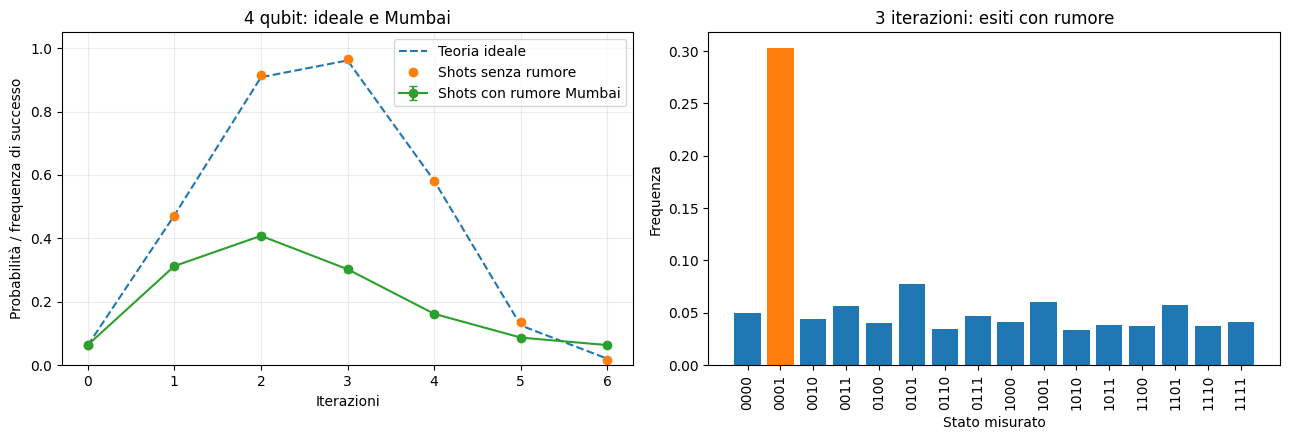

Miglior k misurato tra 0 e 6: 2; frequenza: 0.4082
Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.
Confronto delle frequenze con rumore, a parita' di problema e shots:


backend,fake_manila,fake_mumbai,fake_nairobi
Iterazioni,,,
0,0.0637,0.0637,0.0635
1,0.2205,0.3127,0.3081
2,0.2246,0.4082,0.4038
3,0.1448,0.3027,0.3057
4,0.0952,0.1621,0.1777
5,0.0718,0.0872,0.0886
6,0.0535,0.0635,0.0693


In [142]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(mumbai_results_df.k, mumbai_results_df.theoretical_probability, "--", label="Teoria ideale")
axes[0].plot(mumbai_results_df.k, mumbai_results_df.compiled_ideal_frequency, "o", label="Shots senza rumore")
axes[0].errorbar(mumbai_results_df.k.to_numpy(dtype=float), mumbai_results_df.success_probability.to_numpy(dtype=float),
                 yerr=mumbai_results_df.standard_error.to_numpy(dtype=float), fmt="o-", capsize=3,
                 label="Shots con rumore Mumbai")
axes[0].set(xlabel="Iterazioni", ylabel="Probabilità / frequenza di successo",
            title="4 qubit: ideale e Mumbai", xticks=range(7), ylim=(0, 1.05))
axes[0].legend()
axes[0].grid(alpha=0.25)

mumbai_example = mumbai_results_df[mumbai_results_df.k == 3].iloc[0]
states = [format(i, "04b") for i in range(16)]
frequencies = [mumbai_example["normalized_counts"].get(state, 0) for state in states]
axes[1].bar(states, frequencies, color=["tab:orange" if state == "0001" else "tab:blue" for state in states])
axes[1].set(title="3 iterazioni: esiti con rumore", xlabel="Stato misurato", ylabel="Frequenza")
axes[1].tick_params(axis="x", rotation=90)
fig.tight_layout()
display(fig)
plt.close(fig)

best_mumbai = mumbai_results_df.sort_values(["success_probability", "k"], ascending=[False, True]).iloc[0]
print(f"Miglior k misurato tra 0 e 6: {int(best_mumbai.k)}; frequenza: {best_mumbai.success_probability:.4f}")
print("Ottimo teorico ideale: k=3. Il massimo misurato puo' fluttuare con gli shots.")

print("Confronto delle frequenze con rumore, a parita' di problema e shots:")
backend_comparison = noisy_results_df.pivot(index="k", columns="backend", values="success_probability")
backend_comparison.index.name = "Iterazioni"
display(backend_comparison.round(4))


I risultati mostrano il tipico scontro dell'era NISQ: il vantaggio dell'algoritmo di Grover viene ben presto annullato dal rumore fisico dell'hardware.

* **Picco anticipato (Iterazione 2):** Teoricamente il massimo per 4 qubit è a 3 iterazioni, ma tutti i processori raggiungono il picco reale già a 2 iterazioni. Il rumore introdotto dal massiccio blocco di porte fisiche della terza iterazione supera l'amplificazione algebrica, degradando i risultati.
* **Il limite di Manila:** `fake_manila` si ferma ad appena il 22.4% di probabilità. La sua topologia lineare costringe il compilatore a inserire troppe porte SWAP, saturando il circuito di errori prematuramente.
* **Il salto di Mumbai e Nairobi:** Questi processori raddoppiano le prestazioni, sfiorando il 41% di successo. Topologie più interconnesse (che richiedono meno SWAP) e migliori tempi di coerenza proteggono l'informazione quantistica più a lungo.
* **Collasso nel rumore casuale:** All'iterazione 0, il successo per tutti è intorno a 0.063 (cioè $1/16$, puro caso). Dalla quarta iterazione in poi, l'accumulo inesorabile di errori distrugge la struttura di Grover, facendo crollare di nuovo tutte le probabilità verso il puro rumore bianco (0.063).

## 11. Scaling ideale con la dimensione dello spazio di ricerca

In questo esperimento analizziamo come si comporta l'algoritmo di Grover all'aumentare della complessità del problema. Aumenteremo progressivamente il numero di qubit da $n=2$ fino a $n=7$ (ampliando lo spazio di ricerca $N$ da 4 a 128 elementi), cercando sempre un singolo stato marcato (`00...001`).

Questa simulazione è **ideale** (nessun modello di rumore) e utilizza 4096 shots per ogni esecuzione. Applicheremo sempre il numero intero ottimale di iterazioni.

**Cosa stiamo misurando nei grafici:**
* **Iterazioni Teoriche vs Porte Reali:** La formula $\frac{\pi}{4}\sqrt{N}$ calcola quante "interrogazioni" dobbiamo fare all'Oracolo. Tuttavia, all'aumentare dei qubit, costruire fisicamente l'Oracolo e il Diffusore richiede un numero sempre maggiore di porte base (`u` e `cx`). I grafici metteranno a confronto la teoria con il reale costo circuitale.
* **Tempo di Esecuzione Classico:** Il tempo registrato misura esclusivamente quanto impiega il simulatore software (Aer) sulla CPU classica per completare i calcoli. **Non rappresenta il tempo fisico di un vero processore quantistico**. Poiché eseguiamo una sola misurazione per ogni $n$, il tempo può subire normali fluttuazioni dovute al sistema operativo, per cui non verranno tracciate barre d'errore.

,n,N,k_opt,depth,total_gate_count,two_qubit_gate_count,execution_time,theoretical_probability,success_probability,standard_error
0,2,4,1,5,8,2,0.003597,1.0,1.0,0.0
1,3,8,2,45,63,24,0.005471,0.945312,0.944092,0.00359
2,4,16,3,157,178,84,0.007273,0.961319,0.959473,0.003081
3,5,32,4,513,629,288,0.014634,0.999182,0.998779,0.000546
4,6,64,6,1561,2154,1008,0.039761,0.996586,0.996094,0.000975
5,7,128,8,3027,4471,1984,0.054461,0.99562,0.995605,0.001034


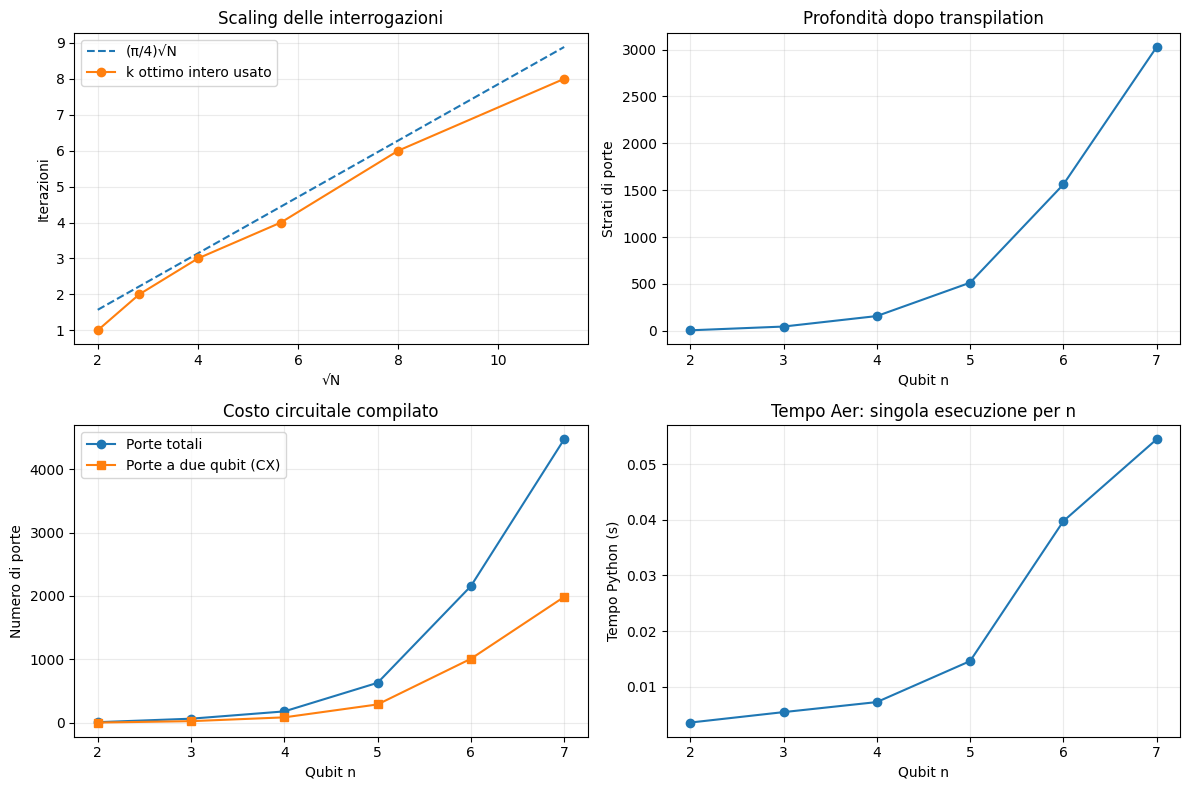

In [143]:
def run_tagged_ideal_experiment(n, marked, k, shots, seed, group):
    """Riusa l'esecuzione ideale e completa i metadati del DataFrame generale."""
    row = run_ideal_experiment(n, marked, k, shots, seed)
    compiled = transpile(build_grover_circuit(n, marked, k, False), make_ideal_backend(seed),
                         optimization_level=IDEAL_OPTIMIZATION_LEVEL, seed_transpiler=seed)
    row.update(p1=0.0, p2=0.0, readout_error=0.0,
               success_probability=row["measured_success_probability"],
               expected_noisy_probability=row["theoretical_probability"],
               actual_basis_gates=",".join(sorted({item.operation.name for item in compiled.data})),
               simulation_method="statevector", experiment_group=group,
               theta=grover_theta(2 ** n, len(marked)),
               k_opt=optimal_grover_iterations(2 ** n, len(marked)))
    return row


# Estende lo schema anche per i batch precedenti, senza cambiare i loro risultati.
RESULT_DTYPES.update({"theta": "Float64", "k_opt": "Int64"})
results_df["theta"] = [grover_theta(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df["k_opt"] = [optimal_grover_iterations(int(N), int(M)) for N, M in zip(results_df.N, results_df.M)]
results_df = results_df.astype(RESULT_DTYPES)
scaling_rows = []
for n in range(2, 8):
    k = optimal_grover_iterations(2 ** n, 1)
    scaling_rows.append(run_tagged_ideal_experiment(n, (format(1, f"0{n}b"),), k,
                        SHOTS_DEFAULT, RANDOM_SEED + 100 * n + k, "scaling"))
scaling_df = pd.DataFrame(scaling_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([results_df[results_df.experiment_group != "scaling"], scaling_df],
                       ignore_index=True).astype(RESULT_DTYPES)
assert len(scaling_df) == 6 and set(scaling_df.n) == set(range(2, 8))
assert np.all(np.diff(scaling_df.k_opt.to_numpy(dtype=int)) >= 0)
assert (scaling_df.k == scaling_df.k_opt).all()
scaling_summary_df = scaling_df[["n", "N", "k_opt", "depth", "total_gate_count",
    "two_qubit_gate_count", "execution_time", "theoretical_probability", "success_probability", "standard_error"]]
display(scaling_summary_df)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
root_N = np.sqrt(scaling_df.N.to_numpy(dtype=float))
axes[0, 0].plot(root_N, np.pi/4 * root_N, "--", label="(π/4)√N")
axes[0, 0].plot(root_N, scaling_df.k_opt, "o-", label="k ottimo intero usato")
axes[0, 0].set(xlabel="√N", ylabel="Iterazioni", title="Scaling delle interrogazioni")
axes[0, 1].plot(scaling_df.n, scaling_df.depth, "o-")
axes[0, 1].set(xlabel="Qubit n", ylabel="Strati di porte", title="Profondità dopo transpilation")
axes[1, 0].plot(scaling_df.n, scaling_df.total_gate_count, "o-", label="Porte totali")
axes[1, 0].plot(scaling_df.n, scaling_df.two_qubit_gate_count, "s-", label="Porte a due qubit (CX)")
axes[1, 0].set(xlabel="Qubit n", ylabel="Numero di porte", title="Costo circuitale compilato")
axes[1, 1].plot(scaling_df.n, scaling_df.execution_time, "o-")
axes[1, 1].set(xlabel="Qubit n", ylabel="Tempo Python (s)", title="Tempo Aer: singola esecuzione per n")
for ax in axes.flat:
    ax.grid(alpha=.25)
for ax in (axes[0, 0], axes[1, 0]):
    ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## 12. Più soluzioni: esperimento ideale a n=5, N=32
Generiamo insiemi annidati e riproducibili con indici $(1+7i)\bmod 2^n$, i=0,...,M-1.
Poiché 7 è coprimo con $2^n$, gli indici non si ripetono prima di aver visitato tutta la base.
Per M=1,2,4,8 eseguiamo k=0,...,8 con 4096 shots per circuito. Il successo è la somma
delle frequenze di **qualsiasi** stato marcato, calcolata dall'helper condiviso.

Per $0<M<N$, $|G\rangle=M^{-1/2}\sum_{w\in W}|w\rangle$ e
$|B\rangle=(N-M)^{-1/2}\sum_{x\notin W}|x\rangle$ restano una base ortonormale
del sottospazio bidimensionale accessibile. Con $\theta=\arcsin\sqrt{M/N}$,
$$|\psi_k\rangle=\cos((2k+1)\theta)|B\rangle+\sin((2k+1)\theta)|G\rangle.$$
La simmetria preserva ampiezze uguali all'interno di ciascun gruppo. Gli assert confrontano
anche lo stato completo con questa formula, oltre alla probabilità totale.

Aumentando M cresce l'angolo di rotazione e il primo massimo richiede meno iterazioni.
La scelta intera può creare plateau in generale; per i quattro M scelti verifichiamo
la diminuzione stretta. La probabilità al k scelto non deve invece crescere monotonicamente
con M, perché l'angolo ottimo può cadere tra interi. Inoltre il nostro oracle marca gli stati
uno alla volta: ridurre le query non implica necessariamente ridurre il costo totale delle porte.

**Esecuzione:** questa sezione usa `run_tagged_ideal_experiment`, definita nella sezione 11.
Se modifichi quella funzione, riesegui prima la cella della sezione 11 e poi questa: il kernel mantiene le vecchie definizioni fino alla riesecuzione.


,M,theta,k_opt,theoretical_probability,measured_probability,standard_error
4,1,0.1777,4,0.9992,0.9995,0.0003
12,2,0.2527,3,0.9613,0.9648,0.0029
20,4,0.3614,2,0.9453,0.9429,0.0036
28,8,0.5236,1,1.0,1.0,0.0


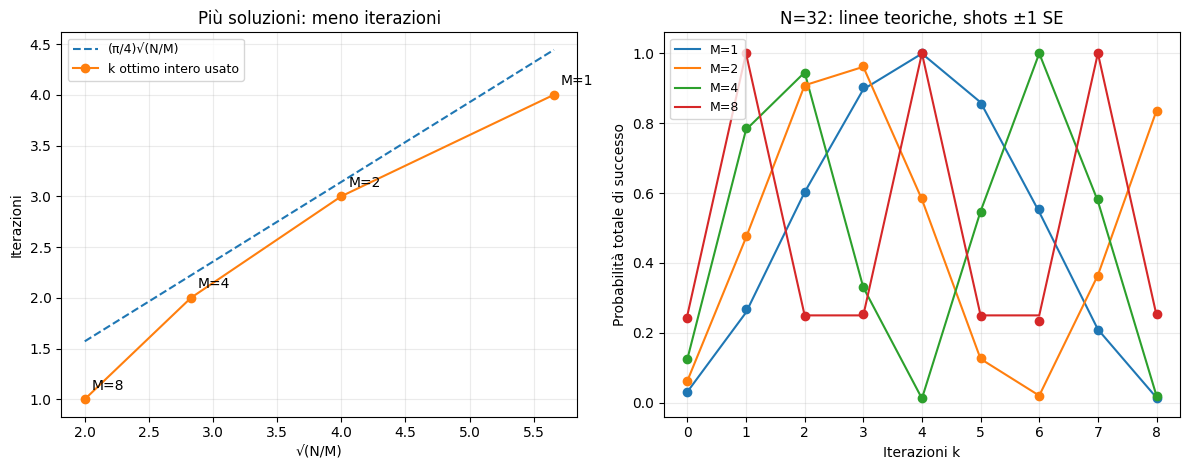

In [144]:
MULTI_N = 5
M_VALUES = (1, 2, 4, 8)

marked_pool = ["00001", "01000", "01111", "10110",
               "11101", "00100", "01011", "10010"]

multi_rows = []
for M in M_VALUES:
    marked = marked_pool[:M]
    for k in range(9):
        seed = RANDOM_SEED + 10000 + 100 * M + k
        result = run_tagged_ideal_experiment(
            MULTI_N, marked, k, SHOTS_DEFAULT, seed, "multiple_solutions"
        )
        multi_rows.append(result)

multiple_solutions_df = pd.DataFrame(multi_rows, columns=RESULT_DTYPES).astype(RESULT_DTYPES)
results_df = pd.concat([
    results_df[results_df.experiment_group != "multiple_solutions"],
    multiple_solutions_df,
], ignore_index=True).astype(RESULT_DTYPES)


multiple_summary_df = multiple_solutions_df[
    multiple_solutions_df.k == multiple_solutions_df.k_opt
][["M", "theta", "k_opt", "theoretical_probability", "success_probability", "standard_error"]]
multiple_summary_df = multiple_summary_df.rename(columns={"success_probability": "measured_probability"})
display(multiple_summary_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
x_values = np.sqrt(32 / multiple_summary_df.M.to_numpy(dtype=float))
order = np.argsort(x_values)
axes[0].plot(x_values[order], np.pi/4 * x_values[order], "--", label="(π/4)√(N/M)")
axes[0].plot(x_values, multiple_summary_df.k_opt, "o-", label="k ottimo intero usato")
for x, row in zip(x_values, multiple_summary_df.itertuples()):
    axes[0].annotate(f"M={row.M}", (x, row.k_opt), xytext=(5, 7), textcoords="offset points")
axes[0].set(xlabel="√(N/M)", ylabel="Iterazioni", title="Più soluzioni: meno iterazioni")
for M, group in multiple_solutions_df.groupby("M"):
    group = group.sort_values("k")
    line, = axes[1].plot(group.k, group.theoretical_probability, label=f"M={M}")
    axes[1].errorbar(group.k.to_numpy(dtype=float), group.success_probability.to_numpy(dtype=float),
                     yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=2, color=line.get_color())
axes[1].set(xlabel="Iterazioni k", ylabel="Probabilità totale di successo",
            title="N=32: linee teoriche, shots ±1 SE", xticks=range(9), ylim=(-.04, 1.06))
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend(fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

## 13. Grover su hardware IBM reale
Seguiamo i quattro passaggi dell'esempio IBM: costruire il circuito, compilarlo
per un dispositivo, inviarlo con `SamplerV2` e visualizzare le misure.
Riutilizziamo l'oracolo e il diffusore manuali del notebook.

Prima prova: **4 qubit, soluzione `0001`, 3 iterazioni, 1024 shots**.
Nel caso ideale la probabilità di successo è circa 0,9613; sull'hardware può diminuire.
Non occorre un processore da esattamente 4 qubit: il circuito usa un sottoinsieme
fisico scelto dal transpiler. Non imponiamo il vincolo arbitrario di 127 qubit.

### 13.1 Configurare l'account (una sola volta)
1. Apri [IBM Quantum Platform](https://quantum.cloud.ibm.com/) con il tuo account.
2. Dalla dashboard crea/copia una **API key**. In **Instances**, seleziona
   l'istanza **Open Plan** con il tuo accesso e copia il suo **CRN**.
   Se non hai un'istanza, creane una Open Plan nella regione `us-east`.
3. Usa il kernel `.venv`, dove `qiskit-ibm-runtime` è già installato.
4. Imposta `CONFIGURE_IBM_ACCOUNT = True` nella cella sotto ed eseguila.
   Incolla la chiave nel campo nascosto e il CRN nel campo successivo.
   Le credenziali vengono salvate localmente dal client IBM, fuori dal repository.
   Non incollare la chiave nel codice o in chat.
5. Riporta `CONFIGURE_IBM_ACCOUNT = False`: nelle esecuzioni successive basta
   caricare l'account salvato con nome `grover-open`.

L'Open Plan offre fino a **10 minuti QPU per finestra mobile di 28 giorni**.
Controlla il residuo nella dashboard: non sono 10 minuti di attesa in coda.
Usiamo un singolo job, senza Session, con limite `max_execution_time=60` secondi QPU.
Questo limite non stima il consumo: se superato il job viene annullato dal servizio.

Fonti IBM: [credenziali](https://quantum.cloud.ibm.com/docs/en/guides/save-credentials),
[Open Plan](https://quantum.cloud.ibm.com/docs/en/guides/plans-overview),
[limite di esecuzione e consumo QPU](https://quantum.cloud.ibm.com/docs/en/guides/max-execution-time).

In [153]:
from getpass import getpass
from pathlib import Path
import json
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

CONFIGURE_IBM_ACCOUNT = False
ACCOUNT_NAME = "grover-open"

if CONFIGURE_IBM_ACCOUNT:
    # Il token non appare nel codice o nell'output del notebook.
    api_key = getpass("API key IBM: ")
    instance_crn = input("CRN dell'istanza Open Plan: ").strip()
    try:
        if not api_key or not instance_crn:
            raise ValueError("Servono API key e CRN dell'istanza.")
        QiskitRuntimeService.save_account(
            channel="ibm_quantum_platform", token=api_key, instance=instance_crn,
            name=ACCOUNT_NAME, overwrite=True,
        )
        print("Account salvato. Riporta CONFIGURE_IBM_ACCOUNT a False.")
    finally:
        del api_key

### 13.2 Preparare il circuito e scegliere il dispositivo
Esegui prima le sezioni iniziali del notebook, fino alla definizione delle funzioni
`build_grover_circuit` e `optimal_grover_iterations` (sezioni 7 e 8).
Questa cella prepara il circuito localmente, senza usare la quota hardware.
Per provare due soluzioni a 4 qubit puoi usare `["0011", "1100"]`: il numero di iterazioni viene ricalcolato.

In [ ]:
# Step 1: usiamo lo stesso problema a 4 qubit dei test con fake backend.
HARDWARE_MARKED = ["0001"]
HARDWARE_SHOTS = 1024
HARDWARE_N = len(HARDWARE_MARKED[0])
HARDWARE_K = optimal_grover_iterations(2 ** HARDWARE_N, len(HARDWARE_MARKED))
hardware_circuit = build_grover_circuit(HARDWARE_N, HARDWARE_MARKED, HARDWARE_K)
hardware_theory = theoretical_success_probability(2 ** HARDWARE_N, len(HARDWARE_MARKED), HARDWARE_K)
print(f"Qubit: {HARDWARE_N}, iterazioni: {HARDWARE_K}, successo ideale: {hardware_theory:.4f}")
print(hardware_circuit.draw(output="text"))

Imposta `CONNECT_IBM = True` ed esegui la cella seguente per connetterti e
compilare. La connessione e la compilazione **non inviano il circuito**.
`least_busy` sceglie un dispositivo operativo accessibile alla tua istanza.
Se l'account non viene trovato, esegui prima la configurazione del punto 13.1.

In [ ]:
# Step 2: selezioniamo il backend reale e adattiamo il circuito alle sue porte.
CONNECT_IBM = False
hardware_service = None
hardware_backend = None
circuit_isa = None

if CONNECT_IBM:
    hardware_service = QiskitRuntimeService(name=ACCOUNT_NAME)
    hardware_backend = hardware_service.least_busy(
        operational=True, simulator=False, min_num_qubits=HARDWARE_N,
    )
    pm = generate_preset_pass_manager(target=hardware_backend.target,
                                      optimization_level=3, seed_transpiler=RANDOM_SEED)
    circuit_isa = pm.run(hardware_circuit)
    print("Backend:", hardware_backend.name)
    print("Profondita' prima/dopo compilazione:", hardware_circuit.depth(), circuit_isa.depth())
else:
    print("Connessione disattivata. Imposta CONNECT_IBM=True quando l'account e' pronto.")

### 13.3 Inviare un solo job e conservare il suo ID
Dopo la compilazione, imposta `SUBMIT_HARDWARE = True` ed esegui questa cella:
**questo passaggio invia il job e usa la quota QPU**. Poi riporta il flag a `False`.
L'ID e i parametri vengono salvati in `results/hardware_grover_4q_job.json`.
Se il file esiste, il codice recupera quel job senza inviarne un altro.
Per una nuova prova scegli un nuovo `HARDWARE_JOB_FILE`, conservando il precedente.
Se l'invio restituisce un errore di rete senza ID, controlla prima **Workloads**
sulla piattaforma: il job potrebbe essere stato accettato.

In [ ]:
# Step 3: invio esplicito oppure recupero di un job gia' salvato.
SUBMIT_HARDWARE = False
HARDWARE_JOB_FILE = Path("results/hardware_grover_4q_job.json")
hardware_job = None
hardware_record = None

if hardware_service is None:
    print("Esegui prima la connessione del punto 13.2.")
elif HARDWARE_JOB_FILE.exists():
    hardware_record = json.loads(HARDWARE_JOB_FILE.read_text(encoding="utf-8"))
    hardware_job = hardware_service.job(hardware_record["job_id"])
    print("Job recuperato:", hardware_job.job_id(), "| Parametri salvati:", hardware_record)
elif SUBMIT_HARDWARE:
    if circuit_isa is None:
        raise RuntimeError("Compila prima il circuito nel punto 13.2.")
    HARDWARE_JOB_FILE.parent.mkdir(parents=True, exist_ok=True)
    sampler = SamplerV2(mode=hardware_backend)
    sampler.options.max_execution_time = 60
    sampler.options.environment.job_tags = ["grover-primo-test"]
    hardware_job = sampler.run([circuit_isa], shots=HARDWARE_SHOTS)
    print("Job inviato:", hardware_job.job_id())  # Conserva l'ID anche se il salvataggio fallisce.
    hardware_record = {
        "job_id": hardware_job.job_id(), "backend": hardware_backend.name,
        "n": HARDWARE_N, "k": HARDWARE_K, "shots": HARDWARE_SHOTS,
        "marked_states": HARDWARE_MARKED, "theoretical_probability": hardware_theory,
        "register_name": hardware_circuit.cregs[0].name,
    }
    HARDWARE_JOB_FILE.write_text(json.dumps(hardware_record, indent=2), encoding="utf-8")
else:
    print("Nessun invio: imposta SUBMIT_HARDWARE=True solo per iniziare la prova.")

### 13.4 Leggere i risultati: tabella e grafici
Questa cella controlla lo stato: se il job non è finito, attendi e riesegui
**solo questa cella**, senza reinviarlo. Puoi anche chiudere il notebook:
alla riapertura connettiti e recupera il job dal file usando il punto 13.3.
La tabella usa i parametri salvati del job, anche se hai poi modificato il circuito.

Il costruttore del notebook chiama il registro classico `c`: per questo leggiamo
il nome salvato, invece di scrivere `.data.meas` come nell'esempio IBM.
I dati reali vengono salvati per ID in `results/hardware_<ID>.json` e `.csv`.
Per il consumo QPU consulta anche Workloads; se le metriche non sono disponibili
immediatamente, puoi rieseguire questa cella in seguito.

In [ ]:
# Step 4: nessun nuovo job, soltanto lettura del risultato e grafici.
hardware_results_df = pd.DataFrame()
if hardware_job is None:
    print("Nessun job caricato: completa il punto 13.3.")
elif not hardware_job.done():
    print("Stato:", hardware_job.status(), "- controlla Workloads e riesegui questa cella quando completato.")
else:
    pub_result = hardware_job.result()[0]
    counts = getattr(pub_result.data, hardware_record["register_name"]).get_counts()
    shots = sum(counts.values())
    marked = hardware_record["marked_states"]
    frequency = sum(counts.get(state, 0) for state in marked) / shots
    row = dict(hardware_record, shots=shots, success_probability=frequency)
    hardware_results_df = pd.DataFrame([row])

    # Salviamo prima i dati reali, indipendentemente dalla disponibilita' delle metriche.
    destination = Path("results") / ("hardware_" + hardware_record["job_id"])
    destination.with_suffix(".json").write_text(
        json.dumps({"experiment": row, "counts": counts}, indent=2), encoding="utf-8")
    hardware_results_df.to_csv(destination.with_suffix(".csv"), index=False)
    display(hardware_results_df[["backend", "n", "k", "shots", "theoretical_probability", "success_probability"]])

    states = [format(i, f"0{row['n']}b") for i in range(2 ** row["n"])]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(states, [counts.get(state, 0) / shots for state in states],
                color=["tab:orange" if state in marked else "tab:blue" for state in states])
    axes[0].set(title="Misure hardware: soluzioni in arancione", xlabel="Stato", ylabel="Frequenza")
    axes[1].bar(["Teoria ideale", "Hardware"], [row["theoretical_probability"], frequency])
    axes[1].set(title="Successo totale sugli stati cercati", ylabel="Probabilita' / frequenza", ylim=(0, 1.05))
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    try:
        usage = hardware_job.metrics().get("usage", {})
        print("Secondi QPU riportati dal servizio:", usage.get("quantum_seconds", "non ancora disponibili"))
    except Exception:
        print("Metriche non disponibili ora: controlla il consumo in Workloads.")

## 14. Raccolta dati e CSV cumulativo
`results_df` contiene i batch ideale e noisy, con gli stessi campi e parametri di rumore aggiuntivi.
`success_probability` è un alias di `measured_success_probability`; la probabilità teorica resta
quella ideale. Per il fake backend `compiled_ideal_frequency` riporta il confronto senza rumore;
`p1`, `p2`, `readout_error` ed `expected_noisy_probability` restano vuoti: non li stimiamo dagli shots.
Il nome del backend, la data del profilo e la versione Runtime identificano la simulazione.
`results/grover_experiments.csv` salva tutte le righe del Run All corrente.
Se presente, `results/grover_ideal_shots.csv` è conservato senza sovrascriverlo, inclusi i suoi tempi.
Se manca, viene ricreato dal batch ideale corrente; i tempi storici non sono recuperabili.
I tempi dei nuovi Run All possono differire. Tuple e counts restano serializzati come JSON.

Il cumulativo comprende anche i gruppi `scaling` e `multiple_solutions`, con theta e k_opt.
I file `grover_scaling.csv` e `grover_multiple_solutions.csv` esportano separatamente i nuovi batch ideali.

In [149]:
results_directory = Path("results")
results_directory.mkdir(parents=True, exist_ok=True)
csv_path = results_directory / "grover_experiments.csv"
csv_frame = results_df.copy()
json_columns = ["marked_states", "basis_gates", "counts", "normalized_counts"]
for column in json_columns:
    csv_frame[column] = csv_frame[column].map(lambda value: json.dumps(value, sort_keys=True))
csv_frame.to_csv(csv_path, index=False, encoding="utf-8")
assert csv_path.is_file() and csv_path.stat().st_size > 0
reloaded = pd.read_csv(csv_path, float_precision="round_trip")
assert list(reloaded.columns) == list(RESULT_DTYPES)
assert len(reloaded) == len(results_df)
for column in json_columns:
    reloaded[column] = reloaded[column].map(json.loads)
for column in ("marked_states", "basis_gates"):
    reloaded[column] = reloaded[column].map(tuple)
reloaded = reloaded.astype(RESULT_DTYPES)
pd.testing.assert_frame_equal(reloaded, results_df, check_exact=True)
for row in reloaded.itertuples():
    assert sum(row.counts.values()) == row.shots
    assert row.normalized_counts == {key: value / row.shots for key, value in row.counts.items()}
    np.testing.assert_allclose(success_probability(row.normalized_counts, row.marked_states),
                               row.measured_success_probability, atol=ATOL, rtol=0)
print(f"CSV verificato: {csv_path.resolve()} ({len(reloaded)} righe)")
assert set(reloaded["mode"]) == {"ideal_shots", "noisy"}
assert (reloaded["mode"] == "ideal_shots").sum() == 66
assert (reloaded["mode"] == "noisy").sum() == len(noisy_results_df)
legacy_path = results_directory / "grover_ideal_shots.csv"
if not legacy_path.exists():
    legacy_columns = list(RESULT_DTYPES)[:list(RESULT_DTYPES).index("p1")]
    csv_frame.loc[csv_frame["experiment_group"] == "ideal_scan", legacy_columns].to_csv(
        legacy_path, index=False, encoding="utf-8")
    print("CSV ideale assente: ricreato dal batch corrente (tempi storici non disponibili).")
if legacy_path.exists():
    legacy = pd.read_csv(legacy_path)
    assert len(legacy) == 24
    # Counts e piano devono rimanere riproducibili; i tempi non sono deterministici.
    for old in legacy.itertuples():
        current = ideal_results_df[(ideal_results_df.n == old.n) & (ideal_results_df.k == old.k)].iloc[0]
        assert current["counts"] == json.loads(old.counts)
        assert current["marked_states"] == tuple(json.loads(old.marked_states))
        assert current["shots"] == old.shots and current["seed"] == old.seed
    print("CSV ideale precedente conservato; counts e piano confermati.")

assert len(reloaded) == 66 + len(noisy_results_df)
assert reloaded.groupby("experiment_group").size().to_dict() == {
    "ideal_scan": 24, "fake_backend": len(noisy_results_df), "scaling": 6, "multiple_solutions": 36}
for group, filename in (("scaling", "grover_scaling.csv"),
                         ("multiple_solutions", "grover_multiple_solutions.csv")):
    selected = csv_frame[csv_frame.experiment_group == group].reset_index(drop=True)
    destination = results_directory / filename
    selected.to_csv(destination, index=False, encoding="utf-8")
    loaded = pd.read_csv(destination, float_precision="round_trip")
    for column in json_columns:
        loaded[column] = loaded[column].map(json.loads)
    for column in ("marked_states", "basis_gates"):
        loaded[column] = loaded[column].map(tuple)
    pd.testing.assert_frame_equal(loaded.astype(RESULT_DTYPES),
        results_df[results_df.experiment_group == group].reset_index(drop=True), check_exact=True)
    print(f"CSV verificato: {filename}, {len(loaded)} righe")


CSV verificato: C:\Users\pier2\Documents\GitHub\QuantumComputing\results\grover_experiments.csv (87 righe)
CSV ideale precedente conservato; counts e piano confermati.
CSV verificato: grover_scaling.csv, 6 righe
CSV verificato: grover_multiple_solutions.csv, 36 righe


## 15. Grafico ideale e overshooting
Per n=4, N=16, M=1 confrontiamo la curva teorica con i punti Statevector.
La curva continua è un'estensione matematica della formula: i circuiti usano soltanto k interi.
Il primo massimo discreto è k=3 (P≈0.9613); a k=6 la probabilità scende a circa 0.0204.
Gli assert verificano crescita fino al picco e diminuzione dopo il picco.

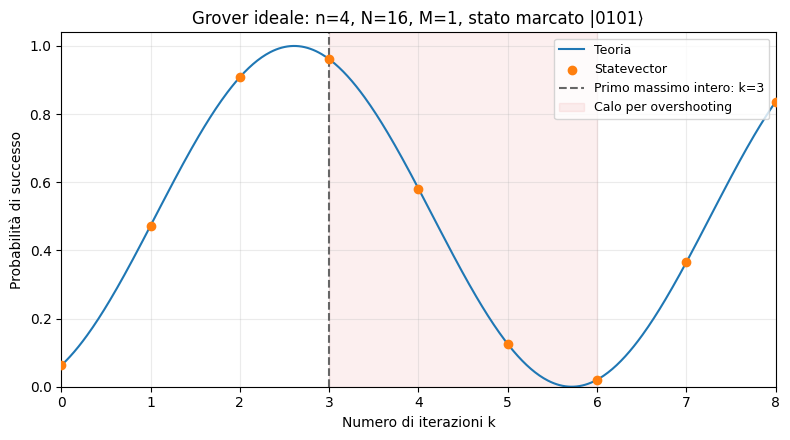

In [150]:
overshooting_df = comparison_df.query("n == 4").sort_values("k")
k_opt = optimal_grover_iterations(16, 1)
assert k_opt == 3
probabilities = overshooting_df.statevector_probability.to_numpy()
assert np.all(np.diff(probabilities[:k_opt + 1]) > 0)
assert np.all(np.diff(probabilities[k_opt:7]) < 0)
assert probabilities[k_opt] > 0.95 and probabilities[6] < 0.03
k_curve = np.linspace(0, 8, 500)
p_curve = np.sin((2 * k_curve + 1) * grover_theta(16, 1)) ** 2
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_curve, p_curve, label="Teoria", color="tab:blue")
ax.scatter(overshooting_df.k, probabilities, label="Statevector", color="tab:orange", zorder=3)
ax.axvline(k_opt, linestyle="--", color="0.4", label=f"Primo massimo intero: k={k_opt}")
ax.axvspan(k_opt, 6, color="tab:red", alpha=0.07, label="Calo per overshooting")
ax.set(xlabel="Numero di iterazioni k", ylabel="Probabilità di successo",
       title="Grover ideale: n=4, N=16, M=1, stato marcato |0101⟩",
       xlim=(0, 8), ylim=(0, 1.04), xticks=range(9))
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

### 15.1 Risultati con shots e scaling delle iterazioni
A: confronto per n=6, con barre di un errore standard binomiale.
B: tutte le misure confrontate con la diagonale di accordo perfetto.
C: il miglior k **osservato nella finestra campionata** per ciascun n viene confrontato
con il k teorico intero e con $(\pi/4)\sqrt N$. In caso di parità scegliamo il k minore.
I punti osservati sono selezionati dalle frequenze, non assegnati dalla teoria: con shots finiti
la scelta può fluttuare. Non attribuiamo al k selezionato una barra binomiale, che riguarda
le probabilità e non l'incertezza sull'argmax. La linea approssimata trascura $-1/2$ e l'arrotondamento.

,n,N,k,theoretical_k_opt,measured_success_probability
1,2,4,1,1,1.0
6,3,8,2,2,0.944092
11,4,16,3,3,0.959473
16,5,32,4,4,0.998779
21,6,64,6,6,0.996094


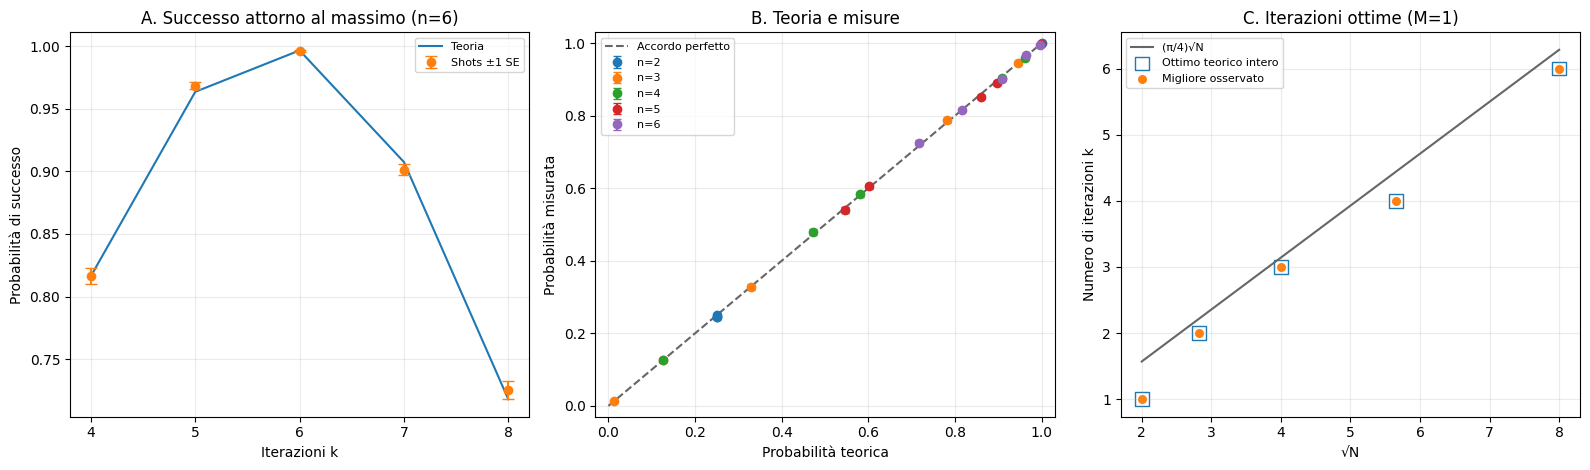

In [151]:
best_observed_df = (ideal_results_df.sort_values(["n", "measured_success_probability", "k"],
                                         ascending=[True, False, True])
                    .groupby("n", sort=True).head(1).sort_values("n").copy())
best_observed_df["theoretical_k_opt"] = [optimal_grover_iterations(int(N), int(M))
                                       for N, M in zip(best_observed_df.N, best_observed_df.M)]
display(best_observed_df[["n", "N", "k", "theoretical_k_opt", "measured_success_probability"]])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sample = ideal_results_df[ideal_results_df.n == 6].sort_values("k")
axes[0].plot(sample.k, sample.theoretical_probability, "-", label="Teoria")
axes[0].errorbar(sample.k.to_numpy(dtype=float), sample.measured_success_probability.to_numpy(dtype=float),
                 yerr=sample.standard_error.to_numpy(dtype=float), fmt="o", capsize=4, label="Shots ±1 SE")
axes[0].set(title="A. Successo attorno al massimo (n=6)", xlabel="Iterazioni k",
            ylabel="Probabilità di successo", xticks=sample.k.to_list())
for n, group in ideal_results_df.groupby("n"):
    axes[1].errorbar(group.theoretical_probability.to_numpy(dtype=float),
                     group.measured_success_probability.to_numpy(dtype=float),
                     yerr=group.standard_error.to_numpy(dtype=float), fmt="o", capsize=3, label=f"n={n}")
axes[1].plot([0, 1], [0, 1], "--", color="0.4", label="Accordo perfetto")
axes[1].set(title="B. Teoria e misure", xlabel="Probabilità teorica",
            ylabel="Probabilità misurata", xlim=(-0.03, 1.03), ylim=(-0.03, 1.03))
sqrt_N = np.sqrt(best_observed_df.N.to_numpy(dtype=float))
x_line = np.linspace(sqrt_N.min(), sqrt_N.max(), 100)
axes[2].plot(x_line, np.pi / 4 * x_line, label="(π/4)√N", color="0.4")
axes[2].scatter(sqrt_N, best_observed_df.theoretical_k_opt, marker="s", s=100,
                facecolors="none", edgecolors="tab:blue", label="Ottimo teorico intero")
axes[2].scatter(sqrt_N, best_observed_df.k, color="tab:orange", s=30, label="Migliore osservato")
axes[2].set(title="C. Iterazioni ottime (M=1)", xlabel="√N", ylabel="Numero di iterazioni k")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 16. Conclusioni della verifica ideale
Gli assert confrontano teoria e Statevector per 27 combinazioni di n e k, con una soluzione
e n=2,3,4. Il caso N=4,M=1 raggiunge lo stato marcato dopo una sola iterazione.
Il caso N=16 mostra crescita, primo massimo a k=3 e calo per overshooting.
I controlli aggiuntivi coprono più soluzioni, n=1, zero iterazioni e misure opzionali.
Questi risultati riguardano l'evoluzione ideale esatta; hardware reale resta una fase futura.

### Controlli minimi della struttura
Verifichiamo anche ambiente e schema popolato dalle esecuzioni ideali con shots;
la tabella dei confronti Statevector è comparison_df.

La serie statistica aggiunge 24 esecuzioni da 4096 shots per n=2,...,6. Le frequenze,
le incertezze e il confronto dei massimi osservati sono riportati sopra; i tempi sono
misure lato Python senza interpretazione come tempo fisico della QPU.

La sezione 10 aggiunge ventuno esecuzioni per 4 qubit: sette per ciascun profilo
FakeManilaV2, FakeNairobiV2 e FakeMumbaiV2,
confrontate con gli stessi circuiti compilati simulati senza rumore.
Non sono stati eseguiti job su hardware reale.

Le sezioni 11 e 12 aggiungono lo scaling ideale fino a n=7 e 36 confronti con M=1,2,4,8.
Le rispettive tabelle riassumono risorse, tempi Python e probabilità. I risultati mostrano
la diminuzione di k_opt da 4 a 1 al crescere di M, senza confonderla con un risparmio garantito di porte.

In [152]:
assert SHOTS_DEFAULT > 0
assert all(isinstance(n, int) and n > 0 for n in N_VALUES)
validate_problem(N_QUBITS_DEFAULT, MARKED_STATES_DEFAULT)
assert 1 <= N_SOLUTIONS_DEFAULT <= SEARCH_SPACE_SIZE
assert not results_df.empty
assert list(results_df.columns) == list(RESULT_DTYPES)
assert {name: str(dtype) for name, dtype in results_df.dtypes.items()} == RESULT_DTYPES
assert make_results_dataframe() is not results_df
assert np.array_equal(
    np.random.default_rng(RANDOM_SEED).random(4),
    np.random.default_rng(RANDOM_SEED).random(4),
)
assert QuantumCircuit(N_QUBITS_DEFAULT).num_qubits == N_QUBITS_DEFAULT
assert make_ideal_backend().options.seed_simulator == RANDOM_SEED
fig = plt.figure()
plt.close(fig)
print("Controlli minimi superati: ambiente e strutture pronti; verifiche Statevector, shots e CSV completate.")

Controlli minimi superati: ambiente e strutture pronti; verifiche Statevector, shots e CSV completate.
